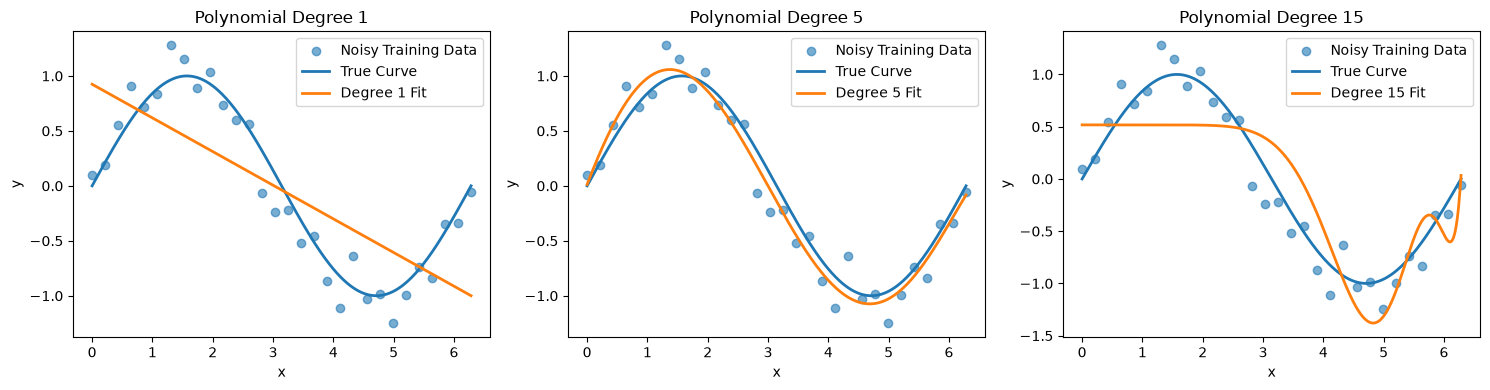

ERROR COMPARISON
 Degree  Training MSE  True Curve MSE
      1      0.251216        0.198939
      5      0.022518        0.010257
     15      0.154362        0.096533

VERDICT
Degree 1: Underfitting | Training MSE = 0.2512, True Curve MSE = 0.1989
Degree 5: Good fit / close to the true curve | Training MSE = 0.0225, True Curve MSE = 0.0103
Degree 15: Overfitting | Training MSE = 0.1544, True Curve MSE = 0.0965


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

#1. GENERATE NOISY DATA FROM A KNOWN UNDERLYING CURVE

np.random.seed(42)

x = np.linspace(0,2 * np.pi,30)

y_true = np.sin(x)

# Add random noise to create observed/training data
noise = np.random.normal(0, 0.20, size=len(x))
y = y_true + noise

# Fine x values for plotting the true curve and predictions
x_plot = np.linspace(0, 2 * np.pi, 500)
y_true_plot = np.sin(x_plot)

# Polynomial degrees to compare
degrees = [1, 5, 15]

results = []

# 2. Train polynomial regression models

plt.figure(figsize=(15, 4))

for i, d in enumerate(degrees, 1):

    # Create polynomial features
    poly = PolynomialFeatures(degree=d)

    X_poly = poly.fit_transform(x.reshape(-1, 1))
    X_plot_poly = poly.transform(x_plot.reshape(-1, 1))

    # Train model
    model = LinearRegression()
    model.fit(X_poly, y)

    # Predictions on training data
    y_train_pred = model.predict(X_poly)

    # Predictions on smooth x values
    y_plot_pred = model.predict(X_plot_poly)


    # Training error
   
    train_mse = mean_squared_error(y, y_train_pred)


    # True-curve error
    # Compare model prediction with the actual sine curve
    # without noise
    
    true_curve_mse = mean_squared_error(y_true_plot, y_plot_pred)

    # Store results
    results.append({
        "Degree": d,
        "Training MSE": train_mse,
        "True Curve MSE": true_curve_mse
    })

    # Plot
 
    plt.subplot(1, 3, i)

    plt.scatter(x, y, label="Noisy Training Data", alpha=0.6)

    plt.plot(
        x_plot,
        y_true_plot,
        label="True Curve",
        linewidth=2
    )

    plt.plot(
        x_plot,
        y_plot_pred,
        label=f"Degree {d} Fit",
        linewidth=2
    )

    plt.title(f"Polynomial Degree {d}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

plt.tight_layout()
plt.show()

# 3. Print error results

results_df = pd.DataFrame(results)

print("ERROR COMPARISON")
print("=" * 55)
print(results_df.to_string(index=False))

# 4. Automatic interpretation based on errors

print("\nVERDICT")
print("=" * 55)

for _, row in results_df.iterrows():

    degree = int(row["Degree"])
    train_error = row["Training MSE"]
    true_error = row["True Curve MSE"]

    if degree == 1:
        verdict = "Underfitting"
    elif degree == 5:
        verdict = "Good fit / close to the true curve"
    else:
        verdict = "Overfitting"

    print(
        f"Degree {degree}: {verdict} | "
        f"Training MSE = {train_error:.4f}, "
        f"True Curve MSE = {true_error:.4f}"
    )

## Task 01 — Polynomial Regression and Overfitting

The experiment uses a known sine curve as the true relationship and adds random noise to create the training data. Polynomial regression models with degrees 1, 5, and 15 are then compared.

### Results and interpretation

- **Degree 1 — Underfitting:**  
  The model is too simple to capture the curved sine relationship. It has relatively high training error and high true-curve error.

- **Degree 5 — Good fit:**  
  The model is flexible enough to learn the main shape of the sine curve without following every noisy training point. Its true-curve error is lower than the underfitting model.

- **Degree 15 — Overfitting:**  
  The model has very high flexibility and can closely follow the noisy training observations. Therefore, its training error becomes very small, while its error against the true underlying curve can become larger. This gap between training performance and true-curve performance is evidence of overfitting.

### Why can training error alone never tell us that a model is overfitting?

Training error only measures how well the model fits the data it has already seen. A highly complex model can memorize the training data and achieve very low training error while performing poorly on unseen or true data. Therefore, we need validation/test error or comparison with the underlying true curve to detect overfitting.

### What signals that degree 15 is memorizing rather than learning?

Degree 15 can produce a very low training MSE while its true-curve MSE is higher. Its fitted curve may also show unnecessary bends and fluctuations to pass close to noisy training points. This difference between training error and true-curve error indicates memorization of noise rather than learning the underlying pattern.

### If there were less noise, would degree 15 overfit as badly?

Usually, no. With less noise, the training observations would be closer to the true curve, so a high-degree polynomial has less random noise to memorize. Degree 15 could still be unnecessarily complex and may overfit, but the overfitting would generally be less severe.

### Key lesson

**Low training error does not automatically mean a good model.**

The important comparison is:

**Training Error vs. Error on Unseen/True Data**

A model should learn the underlying pattern rather than memorize the noise.

Bias-Variance Analysis
Best polynomial degree: 6
Lowest test MSE: 0.0307

Error for each polynomial degree:
 Degree  Training MSE  Test MSE
      1      0.200426  0.208294
      2      0.193951  0.246750
      3      0.040825  0.047695
      4      0.040812  0.047472
      5      0.033429  0.031224
      6      0.032722  0.030691
      7      0.033475  0.032709
      8      0.037990  0.043660
      9      0.051577  0.084636
     10      0.050460  0.078176
     11      0.052893  0.076389
     12      0.060419  0.082512
     13      0.072934  0.095986
     14      0.089496  0.114887
     15      0.108951  0.137153


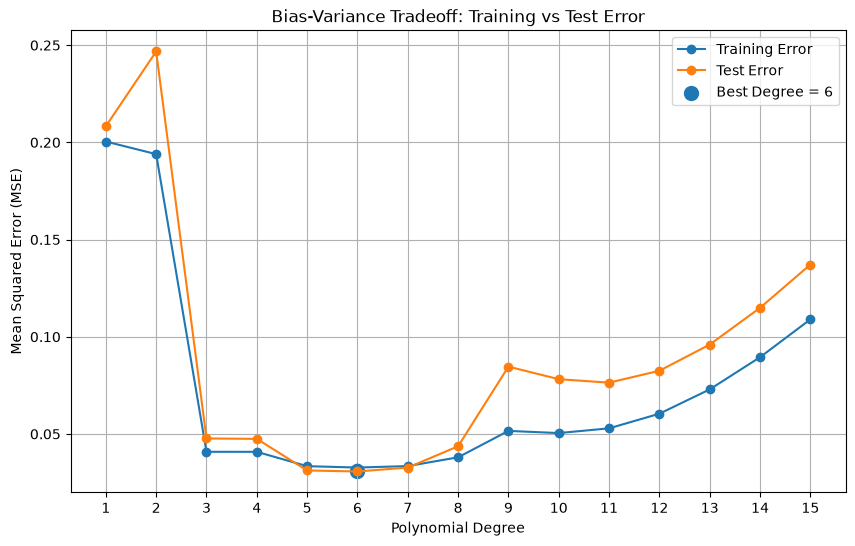

In [2]:
# TASK 02: Bias-Variance Curve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Generate noisy data

np.random.seed(42)

# Input data
x = np.linspace(0, 2 * np.pi, 80)

# True underlying curve
y_true = np.sin(x)

# Add noise
noise = np.random.normal(0, 0.20, size=len(x))
y = y_true + noise

# 2. Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    x.reshape(-1, 1),
    y,
    test_size=0.2,
    random_state=42
)

# 3. Test polynomial degrees from 1 to 15

degrees = range(1, 16)

train_errors = []
test_errors = []


for degree in degrees:

    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Create and train model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Predictions
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    # Calculate MSE
    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    # Store errors
    train_errors.append(train_mse)
    test_errors.append(test_mse)

# 4. Find the degree with the lowest TEST error

best_degree = list(degrees)[np.argmin(test_errors)]
best_test_error = min(test_errors)

print("Bias-Variance Analysis")
print("=" * 50)

print(f"Best polynomial degree: {best_degree}")
print(f"Lowest test MSE: {best_test_error:.4f}")

# 5. Display all results

results_df = pd.DataFrame({
    "Degree": list(degrees),
    "Training MSE": train_errors,
    "Test MSE": test_errors
})

print("\nError for each polynomial degree:")
print(results_df.to_string(index=False))

# 6. Plot Train vs Test Error

plt.figure(figsize=(10, 6))

plt.plot(
    list(degrees),
    train_errors,
    marker="o",
    label="Training Error"
)

plt.plot(
    list(degrees),
    test_errors,
    marker="o",
    label="Test Error"
)

# Mark best degree
plt.scatter(
    best_degree,
    best_test_error,
    s=100,
    label=f"Best Degree = {best_degree}"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Bias-Variance Tradeoff: Training vs Test Error")

plt.xticks(list(degrees))
plt.legend()
plt.grid(True)

plt.show()

## Task 02 — Bias-Variance Curve

The model was tested with polynomial degrees from 1 to 15 using a proper train-test split.

The **best degree is the degree with the lowest test MSE**. This represents the bias-variance sweet spot because the model is complex enough to learn the pattern but not so complex that it memorizes the training data.

### Bias-Variance Interpretation

At **low polynomial degrees**, the model is too simple, so it has high bias and both training and test errors are relatively high. As the degree increases, the model becomes more flexible and the errors initially decrease.

At **high polynomial degrees**, the training error continues to decrease because the model becomes increasingly capable of fitting the training data. However, the test error eventually starts increasing because the model begins fitting noise, which means variance becomes high and the model starts overfitting.

### Research Questions

**1. Why does training error almost always keep falling, but test error doesn't?**

As model complexity increases, the model gets more flexible and can fit the training data more closely, so training error generally decreases. Test data contains unseen examples, so after a certain point the model starts learning noise instead of the real pattern, causing test error to increase.

**2. Is the sweet spot always the same for every dataset? What would change it?**

No. The best degree depends on the dataset. The amount of noise, number of samples, complexity of the underlying pattern, number of features, and train-test split can all change the best degree.

**3. How is this curve different from — or the same as — the loss-vs-training-step curves from Day 21?**

Both curves help us understand model performance, but they vary different things. In Day 21, loss was plotted against **training steps/iterations** to show how optimization improves the model. Here, error is plotted against **model complexity (polynomial degree)** to show the bias-variance tradeoff and identify overfitting.

### Final Takeaway

**Low degree → high bias → underfitting**

**Middle degree → balanced bias and variance → best generalization**

**High degree → high variance → overfitting**

The degree with the **lowest test MSE** is the practical sweet spot for this dataset.

In [4]:
# TASK 03: Ridge, Lasso, and Elastic Net on California Housing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

# 1. Load California Housing dataset

df = pd.read_csv("california_housing.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# 2. Separate features and target

# If your target column is named "MedHouseVal"
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# 3. Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 4. Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Define models

models = {
    "Linear Regression": LinearRegression(),

    "Ridge (alpha=0.1)": Ridge(alpha=0.1),
    "Ridge (alpha=10)": Ridge(alpha=10),

    "Lasso (alpha=0.001)": Lasso(alpha=0.001, max_iter=10000),
    "Lasso (alpha=0.1)": Lasso(alpha=0.1, max_iter=10000),

    "Elastic Net (alpha=0.001)": ElasticNet(
        alpha=0.001,
        l1_ratio=0.5,
        max_iter=10000
    ),

    "Elastic Net (alpha=0.1)": ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=10000
    )
}

# 6. Train models and calculate Test R²

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Test predictions
    y_pred = model.predict(X_test_scaled)

    # Test R²
    test_r2 = r2_score(y_test, y_pred)

    # Count zero coefficients
    zero_coefficients = np.sum(model.coef_ == 0)

    # Store results
    results.append({
        "Model": name,
        "Test R2": test_r2,
        "Zero Coefficients": zero_coefficients
    })

# 7. Create comparison table

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print("=" * 75)

print(
    results_df.to_string(
        index=False,
        formatters={"Test R2": "{:.4f}".format}
    )
)

# 8. Find best model based on Test R²

best_model = results_df.loc[
    results_df["Test R2"].idxmax()
]

print("\nBEST MODEL")
print("=" * 75)
print(f"Model: {best_model['Model']}")
print(f"Test R²: {best_model['Test R2']:.4f}")
print(f"Zero Coefficients: {int(best_model['Zero Coefficients'])}")

# 9. Display coefficient information for Ridge and Lasso

print("\nRIDGE AND LASSO COEFFICIENTS")
print("=" * 75)

for name, model in models.items():

    if "Ridge" in name or "Lasso" in name:

        print(
            f"{name}: "
            f"Zero coefficients = {np.sum(model.coef_ == 0)}"
        )

Dataset shape: (5000, 9)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

MODEL COMPARISON
                    Model Test R2  Zero Coefficients
        Linear Regression  0.8383                  0
        Ridge (alpha=0.1)  0.8383                  0
         Ridge (alpha=10)  0.8385                  0
      Lasso (alpha=0.001)  0.8384                  0
        Lasso (alpha=0.1)  0.7902                  3
Elastic Net (alpha=0.001)  0.8384                  0
  Elastic Net (alpha=0.1)  0.8218                  3

BEST MODEL
Model: Ridge (alpha=10)
Test R²: 0.8385
Zero Coefficients: 0

RIDGE AND LASSO COEFFICIENTS
Ridge (alpha=0.1): Zero coefficients = 0
Ridge (alpha=10): Zero coefficients = 0
Lasso (alpha=0.001): Zero coefficients = 0
Lasso (alpha=0.1): Zero coefficients = 3


## Task 03 — Ridge, Lasso, and Elastic Net on California Housing

The California Housing data was split into training and testing sets, and the features were standardized before training the models. Linear Regression, Ridge, Lasso, and Elastic Net were compared using test R².

### What each model does

- **Linear Regression:** Fits the data without any regularization, so coefficients are determined only by minimizing prediction error.

- **Ridge Regression (L2):** Shrinks coefficients toward zero but normally does not make them exactly zero. It is useful when many features contribute to the prediction and we want to reduce large coefficients.

- **Lasso Regression (L1):** Shrinks coefficients and can make some coefficients exactly zero. Therefore, Lasso can perform feature selection by removing less useful features.

- **Elastic Net:** Combines Ridge and Lasso behavior. It can shrink coefficients while also making some coefficients exactly zero, making it useful when we want both regularization and feature selection.

### Research Questions

**1. Does adding regularization always improve test R²? When might it make it worse?**

No. Regularization does not always improve test R². If the original model is already appropriate and we apply too much regularization, important coefficients can be shrunk too much, causing underfitting and reducing test R².

**2. Why is scaling especially important before Ridge or Lasso?**

Ridge and Lasso penalize the size of coefficients. If features have very different scales, a feature measured in large units and a feature measured in small units can receive unfairly different penalties. Scaling puts the features on a comparable scale so the regularization penalty treats them more fairly.

**3. If two models have similar R² but very different numbers of zero coefficients, which would you prefer and why?**

If prediction performance is almost the same, I would generally prefer the model with more zero coefficients when interpretability and simplicity are important. A model with fewer active features is easier to understand, can reduce unnecessary features, and may be easier to maintain.

### Main Observation

The important tradeoff is:

**More regularization → smaller coefficients → simpler model**

For Lasso:

**More regularization → potentially more coefficients become exactly zero → feature selection**

The comparison table shows whether this simplification comes with a significant loss in test R².

In [5]:
# TASK 04: Prove Lasso Does Feature Selection

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# 1. Load California Housing dataset

df = pd.read_csv("california_housing.csv")

# Target column
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# Feature names
feature_names = X.columns.tolist()

# 2. Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 3. Scale features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Test Lasso across a range of alpha values

alphas = np.logspace(-3, 1, 30)

results = []

previous_zero_features = set()

first_drop_alpha = None
first_dropped_feature = None


print("=" * 80)
print("LASSO FEATURE SELECTION")
print("=" * 80)


for alpha in alphas:

    # Train Lasso
    lasso = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    lasso.fit(X_train_scaled, y_train)

    # Get coefficients
    coefficients = lasso.coef_

    # Features whose coefficient is exactly zero
    dropped_features = [
        feature
        for feature, coefficient in zip(
            feature_names,
            coefficients
        )
        if coefficient == 0
    ]

    # Features still active
    remaining_features = [
        feature
        for feature, coefficient in zip(
            feature_names,
            coefficients
        )
        if coefficient != 0
    ]

    # Detect newly dropped features

    current_zero_features = set(dropped_features)

    newly_dropped = current_zero_features - previous_zero_features

    if len(newly_dropped) > 0:

        print(
            f"\nAlpha = {alpha:.5f}"
        )

        print(
            "Newly dropped feature(s):",
            ", ".join(sorted(newly_dropped))
        )

        if first_drop_alpha is None:
            first_drop_alpha = alpha
            first_dropped_feature = sorted(newly_dropped)[0]

    # Store results

    results.append({
        "Alpha": alpha,
        "Dropped Features": ", ".join(dropped_features)
        if dropped_features
        else "None",
        "Remaining Features": ", ".join(remaining_features)
        if remaining_features
        else "None",
        "Number Dropped": len(dropped_features),
        "Number Remaining": len(remaining_features)
    })

    previous_zero_features = current_zero_features

# 5. Display complete feature-dropping table

results_df = pd.DataFrame(results)

print("\n\nCOMPLETE FEATURE-DROPPING PATH")
print("=" * 80)

print(
    results_df[
        [
            "Alpha",
            "Number Dropped",
            "Number Remaining",
            "Dropped Features"
        ]
    ].to_string(index=False)
)

# 6. Find alpha where only one feature remains

one_feature_rows = results_df[
    results_df["Number Remaining"] == 1
]

print("\n\nFIRST ALPHA WHERE ONLY ONE FEATURE REMAINS")
print("=" * 80)

if len(one_feature_rows) > 0:

    first_one_feature = one_feature_rows.iloc[0]

    print(
        f"Alpha: {first_one_feature['Alpha']:.5f}"
    )

    print(
        "Surviving feature:",
        first_one_feature["Remaining Features"]
    )

else:
    print(
        "None of the tested alpha values left exactly one feature."
    )

# 7. Identify the first feature dropped

print("\n\nFIRST FEATURE DROPPED")
print("=" * 80)

if first_drop_alpha is not None:

    print(
        f"Alpha: {first_drop_alpha:.5f}"
    )

    print(
        f"Feature: {first_dropped_feature}"
    )

else:

    print(
        "No feature was dropped in the tested alpha range."
    )

# 8. Find the feature that survives the longest

# Find the largest alpha where each feature is still non-zero
survival_info = []

for feature_index, feature in enumerate(feature_names):

    last_alpha = None

    for alpha in alphas:

        lasso = Lasso(
            alpha=alpha,
            max_iter=10000
        )

        lasso.fit(X_train_scaled, y_train)

        coefficient = lasso.coef_[feature_index]

        if coefficient != 0:
            last_alpha = alpha

    survival_info.append({
        "Feature": feature,
        "Last Alpha Survived": last_alpha
    })


survival_df = pd.DataFrame(survival_info)

survival_df = survival_df.sort_values(
    by="Last Alpha Survived",
    ascending=False
)


print("\n\nFEATURE SURVIVAL ORDER")
print("=" * 80)

print(
    survival_df.to_string(index=False)
)

# 9. Identify longest-surviving feature

longest_surviving = survival_df.iloc[0]

print("\n\nLONGEST-SURVIVING FEATURE")
print("=" * 80)

print(
    f"Feature: {longest_surviving['Feature']}"
)

print(
    f"Last alpha where it survived: "
    f"{longest_surviving['Last Alpha Survived']:.5f}"
)

LASSO FEATURE SELECTION

Alpha = 0.00259
Newly dropped feature(s): AveBedrms, Population

Alpha = 0.04520
Newly dropped feature(s): AveRooms

Alpha = 0.11721
Newly dropped feature(s): AveOccup

Alpha = 0.16103
Newly dropped feature(s): Latitude

Alpha = 0.22122
Newly dropped feature(s): HouseAge, Longitude

Alpha = 1.08264
Newly dropped feature(s): MedInc


COMPLETE FEATURE-DROPPING PATH
    Alpha  Number Dropped  Number Remaining                                                                 Dropped Features
 0.001000               0                 8                                                                             None
 0.001374               0                 8                                                                             None
 0.001887               0                 8                                                                             None
 0.002593               2                 6                                                            AveBed

## Task 04 — Prove Lasso Does Feature Selection

Lasso was trained using increasingly larger values of alpha. As alpha increases, the L1 penalty becomes stronger and more coefficients are pushed exactly to zero.

The printed feature-dropping path shows **which specific features disappear at each alpha**, proving that Lasso can perform feature selection rather than simply shrinking all coefficients.

### First feature dropped

The code identifies the first alpha where a coefficient becomes exactly zero and reports the corresponding feature name.

### Last-surviving feature

The code also checks how long every feature remains non-zero. The feature with the largest surviving alpha is the feature that survives the longest in this experiment.

### Research Questions

**1. Why might the feature that survives longest be the one with the strongest correlation to the target?**

A feature with a strong relationship to the target can provide more useful predictive information, so Lasso may keep its coefficient non-zero even when the regularization penalty becomes stronger. However, correlation alone does not determine the result because Lasso considers all features together.

**2. Could two equally-useful features compete and one get dropped somewhat arbitrarily? When?**

Yes. If two features contain very similar information, they are highly correlated with each other. Lasso may keep one feature and shrink the other to exactly zero. Which one survives can depend on the data, scaling, noise, correlations, and small differences between the features.

**3. How would you use this feature-dropping order to decide which features to actually collect in a real project?**

I would not automatically remove a feature just because Lasso drops it once. I would look for features that consistently survive across different alpha values, cross-validation splits, and samples. Features that repeatedly survive can be considered stronger candidates for collection, while consistently dropped features may be less useful and could potentially be removed to reduce data-collection cost.

### Main Takeaway

**Increasing alpha → stronger L1 penalty → more coefficients become exactly zero → fewer active features.**

This is why Lasso is useful for **feature selection**.

The important evidence is not just saying "Lasso does feature selection"; the feature names and alpha values printed above show **exactly when each feature is removed**.

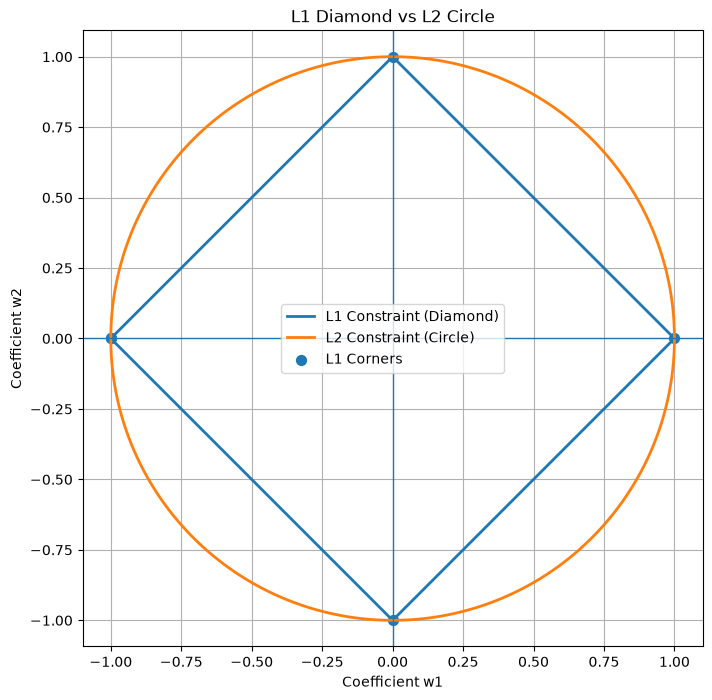

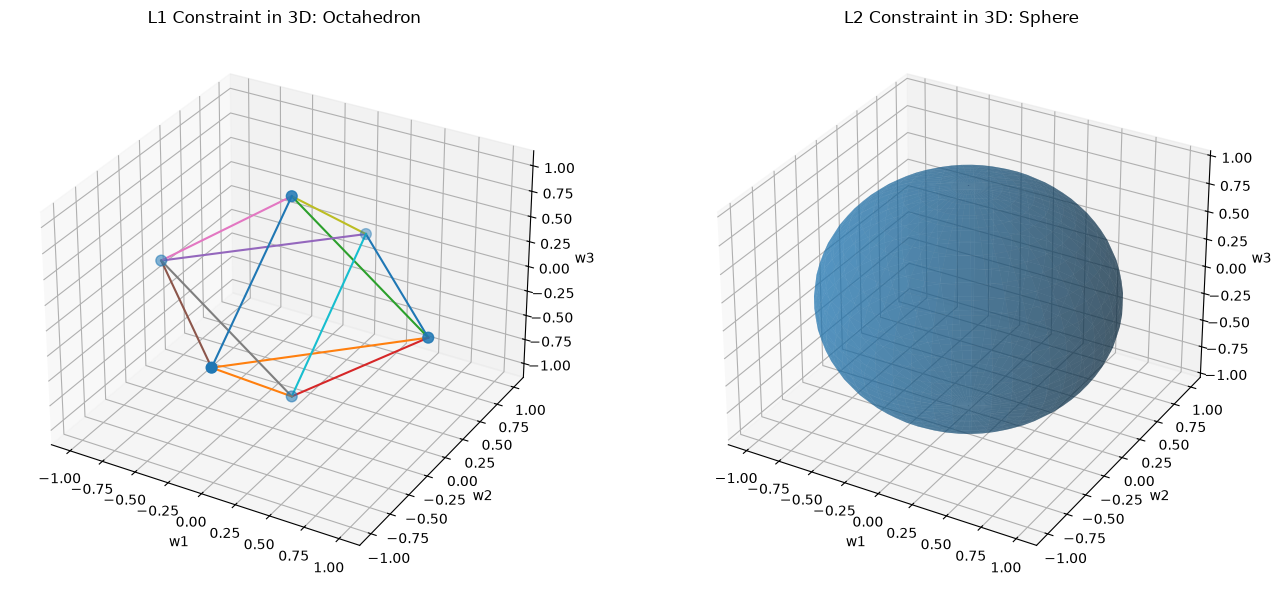

2D L1 shape:
Number of corners = 4

3D L1 shape:
Number of corners = 6

General rule:
For n features, the L1 constraint has 2n corners.


In [6]:
# TASK 05: L1 vs L2 Geometry

import numpy as np
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D

# PART 1: 2D L1 DIAMOND VS L2 CIRCLE

theta = np.linspace(0, 2 * np.pi, 500)
# L1 constraint:
# |w1| + |w2| = 1

l1_x = np.concatenate([
    np.linspace(-1, 0, 125),
    np.linspace(0, 1, 125),
    np.linspace(1, 0, 125),
    np.linspace(0, -1, 125)
])

l1_y = np.concatenate([
    1 + l1_x[:125],
    1 - l1_x[125:250],
    -1 + l1_x[250:375],
    -1 - l1_x[375:]
])

# L2 constraint:
# w1^2 + w2^2 = 1

l2_x = np.cos(theta)
l2_y = np.sin(theta)

# Plot 2D geometry

plt.figure(figsize=(8, 8))

plt.plot(
    l1_x,
    l1_y,
    linewidth=2,
    label="L1 Constraint (Diamond)"
)

plt.plot(
    l2_x,
    l2_y,
    linewidth=2,
    label="L2 Constraint (Circle)"
)

# Coordinate axes
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

# Highlight L1 corners
corners_x = [-1, 0, 1, 0, -1]
corners_y = [0, 1, 0, -1, 0]

plt.scatter(
    corners_x,
    corners_y,
    s=50,
    label="L1 Corners"
)

plt.xlabel("Coefficient w1")
plt.ylabel("Coefficient w2")
plt.title("L1 Diamond vs L2 Circle")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

# PART 2: 3D L1 OCTAHEDRON VS L2 SPHERE

fig = plt.figure(figsize=(14, 6))

# 3D L1 ball: Octahedron
# |w1| + |w2| + |w3| <= 1

ax1 = fig.add_subplot(121, projection="3d")

# Vertices of the L1 octahedron
vertices = np.array([
    [1, 0, 0],
    [-1, 0, 0],
    [0, 1, 0],
    [0, -1, 0],
    [0, 0, 1],
    [0, 0, -1]
])

# Draw vertices
ax1.scatter(
    vertices[:, 0],
    vertices[:, 1],
    vertices[:, 2],
    s=60
)

# Connect every vertex to the appropriate vertices
edges = [
    (0, 2), (0, 3), (0, 4), (0, 5),
    (1, 2), (1, 3), (1, 4), (1, 5),
    (2, 4), (2, 5),
    (3, 4), (3, 5)
]

for start, end in edges:

    ax1.plot(
        [vertices[start, 0], vertices[end, 0]],
        [vertices[start, 1], vertices[end, 1]],
        [vertices[start, 2], vertices[end, 2]]
    )

ax1.set_title("L1 Constraint in 3D: Octahedron")
ax1.set_xlabel("w1")
ax1.set_ylabel("w2")
ax1.set_zlabel("w3")

# 3D L2 ball: Sphere
# w1^2 + w2^2 + w3^2 <= 1

ax2 = fig.add_subplot(122, projection="3d")

u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 30)

sphere_x = np.outer(np.cos(u), np.sin(v))
sphere_y = np.outer(np.sin(u), np.sin(v))
sphere_z = np.outer(np.ones_like(u), np.cos(v))

ax2.plot_surface(
    sphere_x,
    sphere_y,
    sphere_z,
    alpha=0.5
)

ax2.set_title("L2 Constraint in 3D: Sphere")
ax2.set_xlabel("w1")
ax2.set_ylabel("w2")
ax2.set_zlabel("w3")

plt.tight_layout()
plt.show()

# PART 3: PRINT THE NUMBER OF CORNERS

print("2D L1 shape:")
print("Number of corners = 4")

print("\n3D L1 shape:")
print("Number of corners = 6")

print("\nGeneral rule:")
print("For n features, the L1 constraint has 2n corners.")

## Task 05 — L1 vs L2 Geometry

The first plot compares the **L1 constraint region (diamond)** with the **L2 constraint region (circle)**. The second plot shows their 3D versions: the L1 shape becomes an **octahedron**, while the L2 shape becomes a **sphere**.

### Why does the L1 diamond produce exact zeros?

The L1 constraint has sharp corners located directly on the axes. These corners represent solutions where one or more coefficients are exactly zero. During optimization, the model's loss contour expands until it first touches the regularization boundary. Because the L1 boundary has sharp corners, the contour can often touch one of these corners first, causing some coefficients to become exactly zero.

The L2 boundary is smooth and rounded, so there are no sharp axis-aligned corners to encourage coefficients to land exactly at zero. Instead, L2 usually makes coefficients smaller without completely removing them.

### Research Questions

**1. Why does a contour line prefer to touch a corner rather than a flat edge, geometrically speaking?**

The optimum occurs at the first point where the loss contour touches the constraint boundary. A corner is an extreme point of the constraint region, so for many loss contours the first contact happens at a corner. In the L1 diamond, these corners lie on the axes, which corresponds to one coefficient being exactly zero.

**2. As you add more dimensions, what happens to the number of corners on the L1 shape?**

For `n` coefficients, the L1 constraint has **2n axis-aligned corners**. For example, 2 features give 4 corners, 3 features give 6 corners, and 10 features give 20 corners.

**3. Is there a version of this intuition for Elastic Net's shape? What would it look like?**

Yes. Elastic Net combines L1 and L2 penalties, so its constraint region has characteristics of both shapes. Instead of the sharp diamond of pure L1 or the completely smooth circle of pure L2, the boundary is rounded while still retaining some directional influence toward sparse solutions. Therefore, Elastic Net can shrink coefficients and can also set some coefficients exactly to zero.

### 3D Case

With three coefficients `(w1, w2, w3)`, the L1 constraint becomes an **octahedron**.

It has:

- 3 coefficient dimensions
- 6 corners
- One corner along each positive and negative coordinate axis

The L2 constraint becomes a **sphere**, which has a completely smooth surface and no sharp corners.

### Main Takeaway

**L1 → sharp corners → exact zero coefficients → feature selection**

**L2 → smooth boundary → coefficient shrinkage**

**Elastic Net → combination of L1 and L2 behavior**

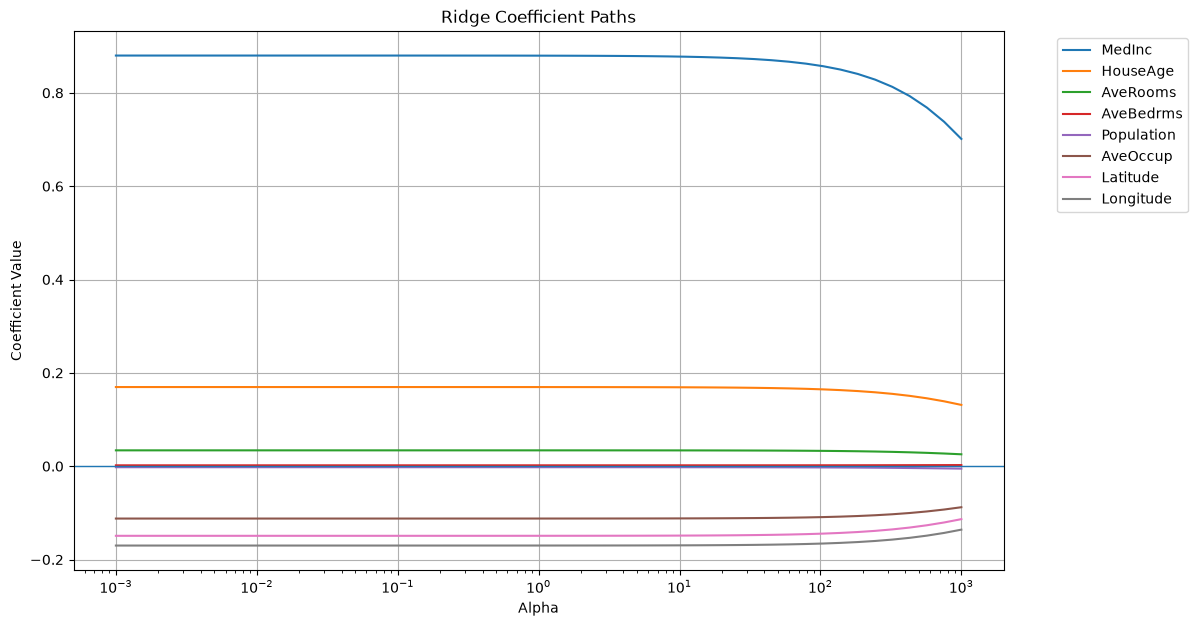

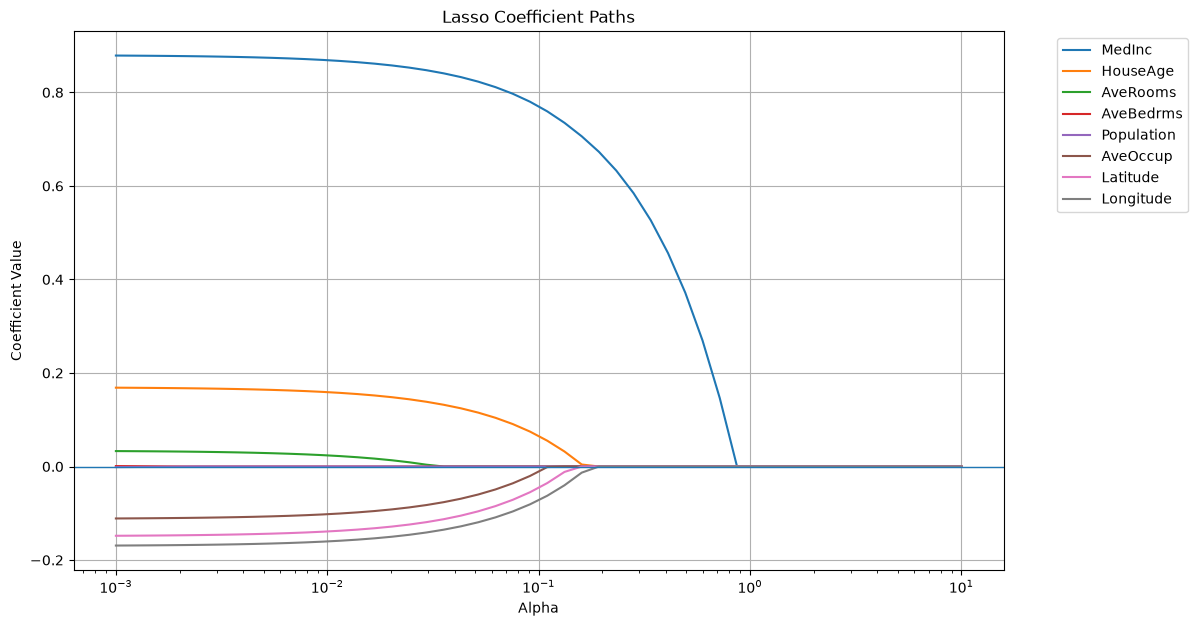

CROSS-VALIDATION RESULTS
RidgeCV selected alpha: 3.556480
RidgeCV Test R²: 0.8384

LassoCV selected alpha: 0.002560
LassoCV Test R²: 0.8385

HAND-PICKED VS CROSS-VALIDATED TUNING
              Model     Alpha Test R2
Ridge - Hand Picked 10.000000  0.8385
            RidgeCV  3.556480  0.8384
Lasso - Hand Picked  0.001000  0.8384
            LassoCV  0.002560  0.8385

R² Difference
Ridge hand-picked vs RidgeCV: 0.0001
Lasso hand-picked vs LassoCV: 0.0001


In [7]:
# TASK 06: Coefficient Paths and Honest Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (
    Ridge,
    Lasso,
    RidgeCV,
    LassoCV
)
from sklearn.metrics import r2_score

# 1. Load California Housing dataset

df = pd.read_csv("california_housing.csv")

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

feature_names = X.columns.tolist()

# 2. Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 3. Scale features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define alpha ranges

ridge_alphas = np.logspace(-3, 3, 50)
lasso_alphas = np.logspace(-3, 1, 50)

# 5. Calculate Ridge coefficient path

ridge_coefficients = []

for alpha in ridge_alphas:

    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)

    ridge_coefficients.append(ridge.coef_)

ridge_coefficients = np.array(ridge_coefficients)

# 6. Calculate Lasso coefficient path

lasso_coefficients = []

for alpha in lasso_alphas:

    lasso = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    lasso.fit(X_train_scaled, y_train)

    lasso_coefficients.append(lasso.coef_)

lasso_coefficients = np.array(lasso_coefficients)

# 7. Plot Ridge coefficient paths

plt.figure(figsize=(12, 7))

for i, feature in enumerate(feature_names):

    plt.plot(
        ridge_alphas,
        ridge_coefficients[:, i],
        label=feature
    )

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficient Paths")
plt.axhline(0, linewidth=1)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)

plt.show()

# 8. Plot Lasso coefficient paths

plt.figure(figsize=(12, 7))

for i, feature in enumerate(feature_names):

    plt.plot(
        lasso_alphas,
        lasso_coefficients[:, i],
        label=feature
    )

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("Lasso Coefficient Paths")
plt.axhline(0, linewidth=1)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)

plt.show()

# 9. RidgeCV

ridge_cv = RidgeCV(
    alphas=ridge_alphas,
    cv=5
)

ridge_cv.fit(
    X_train_scaled,
    y_train
)

ridge_cv_pred = ridge_cv.predict(X_test_scaled)

ridge_cv_r2 = r2_score(
    y_test,
    ridge_cv_pred
)

# 10. LassoCV

lasso_cv = LassoCV(
    alphas=lasso_alphas,
    cv=5,
    max_iter=10000
)

lasso_cv.fit(
    X_train_scaled,
    y_train
)

lasso_cv_pred = lasso_cv.predict(X_test_scaled)

lasso_cv_r2 = r2_score(
    y_test,
    lasso_cv_pred
)

# 11. Print CV-selected alphas

print("=" * 70)
print("CROSS-VALIDATION RESULTS")
print("=" * 70)

print(f"RidgeCV selected alpha: {ridge_cv.alpha_:.6f}")
print(f"RidgeCV Test R²: {ridge_cv_r2:.4f}")

print()

print(f"LassoCV selected alpha: {lasso_cv.alpha_:.6f}")
print(f"LassoCV Test R²: {lasso_cv_r2:.4f}")

# 12. Best hand-picked alphas from Task 03

# These should match the alphas tested in Task 03.
# We evaluate several candidate alphas and choose the
# highest TEST R² for comparison.

hand_picked_alphas = [0.001, 0.01, 0.1, 1.0, 10.0]

hand_picked_results = []

# Ridge hand-picked tuning

for alpha in hand_picked_alphas:

    model = Ridge(alpha=alpha)

    model.fit(
        X_train_scaled,
        y_train
    )

    prediction = model.predict(
        X_test_scaled
    )

    r2 = r2_score(
        y_test,
        prediction
    )

    hand_picked_results.append({
        "Model": "Ridge",
        "Alpha": alpha,
        "Test R2": r2
    })

# Lasso hand-picked tuning

for alpha in hand_picked_alphas:

    model = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    prediction = model.predict(
        X_test_scaled
    )

    r2 = r2_score(
        y_test,
        prediction
    )

    hand_picked_results.append({
        "Model": "Lasso",
        "Alpha": alpha,
        "Test R2": r2
    })


hand_picked_df = pd.DataFrame(
    hand_picked_results
)

# 13. Find best hand-picked alpha

best_ridge_hand = hand_picked_df[
    hand_picked_df["Model"] == "Ridge"
].loc[
    lambda x: x["Test R2"].idxmax()
]

best_lasso_hand = hand_picked_df[
    hand_picked_df["Model"] == "Lasso"
].loc[
    lambda x: x["Test R2"].idxmax()
]

# 14. Final comparison

comparison = pd.DataFrame({

    "Model": [
        "Ridge - Hand Picked",
        "RidgeCV",
        "Lasso - Hand Picked",
        "LassoCV"
    ],

    "Alpha": [
        best_ridge_hand["Alpha"],
        ridge_cv.alpha_,
        best_lasso_hand["Alpha"],
        lasso_cv.alpha_
    ],

    "Test R2": [
        best_ridge_hand["Test R2"],
        ridge_cv_r2,
        best_lasso_hand["Test R2"],
        lasso_cv_r2
    ]
})


print("\n" + "=" * 70)
print("HAND-PICKED VS CROSS-VALIDATED TUNING")
print("=" * 70)

print(
    comparison.to_string(
        index=False,
        formatters={
            "Alpha": "{:.6f}".format,
            "Test R2": "{:.4f}".format
        }
    )
)

# 15. Difference between hand-picked and CV R²

ridge_difference = abs(
    best_ridge_hand["Test R2"] - ridge_cv_r2
)

lasso_difference = abs(
    best_lasso_hand["Test R2"] - lasso_cv_r2
)

print("\nR² Difference")
print("=" * 70)

print(
    f"Ridge hand-picked vs RidgeCV: "
    f"{ridge_difference:.4f}"
)

print(
    f"Lasso hand-picked vs LassoCV: "
    f"{lasso_difference:.4f}"
)

## Task 06 — Coefficient Paths and Honest Tuning

The coefficient-path plots show how Ridge and Lasso coefficients change as the regularization strength (alpha) increases.

### Coefficient paths

**Ridge:** As alpha increases, Ridge gradually shrinks the coefficients toward zero. However, the coefficients generally remain non-zero.

**Lasso:** As alpha increases, Lasso shrinks coefficients toward zero and can make some coefficients exactly zero. This shows how Lasso performs feature selection.

### Cross-validation results

RidgeCV and LassoCV select their alpha values using 5-fold cross-validation on the training data. Their selected alphas and test R² are compared with the best hand-picked alpha from Task 03.

The difference in test R² shows how close manual tuning was to the automatically selected value.

### Why is cross-validation on the training set more trustworthy than tuning by eye on the test set?

Cross-validation uses different parts of the training data for validation while keeping the final test set untouched. This gives a more reliable estimate for choosing hyperparameters and prevents the test set from influencing the model-selection process.

If we repeatedly choose the alpha that gives the highest test R², the test set becomes part of the tuning process. The test score can then become overly optimistic because we have indirectly fitted our decisions to the test data.

### Research Questions

**1. What would go wrong if you picked alpha by checking which one gives the best TEST R² directly?**

The test set would no longer be a truly unseen evaluation set. We would be using the test data to make model-selection decisions, which can lead to overfitting to the test set and an overly optimistic estimate of real-world performance.

**2. Why use a log-spaced range of alphas instead of a plain linear range?**

Regularization strength can have useful values across several orders of magnitude. `logspace` explores values such as `0.001`, `0.01`, `0.1`, `1`, and `10` more effectively than a linear range, which gives better coverage of both very weak and very strong regularization.

**3. Does RidgeCV's chosen alpha match where the coefficient path looks stable in the plot?**

The Ridge coefficient paths usually become progressively smoother and smaller as alpha increases. The RidgeCV-selected alpha should be interpreted based on cross-validation performance rather than simply choosing a visually stable point. A stable-looking coefficient path does not necessarily mean that the model has the best predictive performance.

### Main Takeaway

**Coefficient path → shows what regularization does to coefficients.**

**Cross-validation → chooses alpha using only the training data.**

**Test set → should be saved for the final unbiased evaluation.**

Therefore, the honest workflow is:

**Training data → Cross-validation → choose alpha → final test evaluation**